In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os

folders = os.listdir("/content/drive/MyDrive")

for folder in folders:
    if "SkillMe" in folder:
        print("Folder Name:", repr(folder))

Folder Name: 'SkillMe_Projects '


In [3]:
import os

project_path = "/content/drive/MyDrive/SkillMe_Projects "

print(os.path.exists(project_path))

os.chdir(project_path)

print("Project Folder Connected Successfully!")
print(os.getcwd())

True
Project Folder Connected Successfully!
/content/drive/MyDrive/SkillMe_Projects 


In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits

In [5]:
digits = load_digits()

print("Dataset loaded successfully!")
print("Images Shape:", digits.images.shape)
print("Data Shape:", digits.data.shape)
print("Target Shape:", digits.target.shape)

Dataset loaded successfully!
Images Shape: (1797, 8, 8)
Data Shape: (1797, 64)
Target Shape: (1797,)


In [6]:
print("First 10 Labels:")
print(digits.target[:10])

First 10 Labels:
[0 1 2 3 4 5 6 7 8 9]


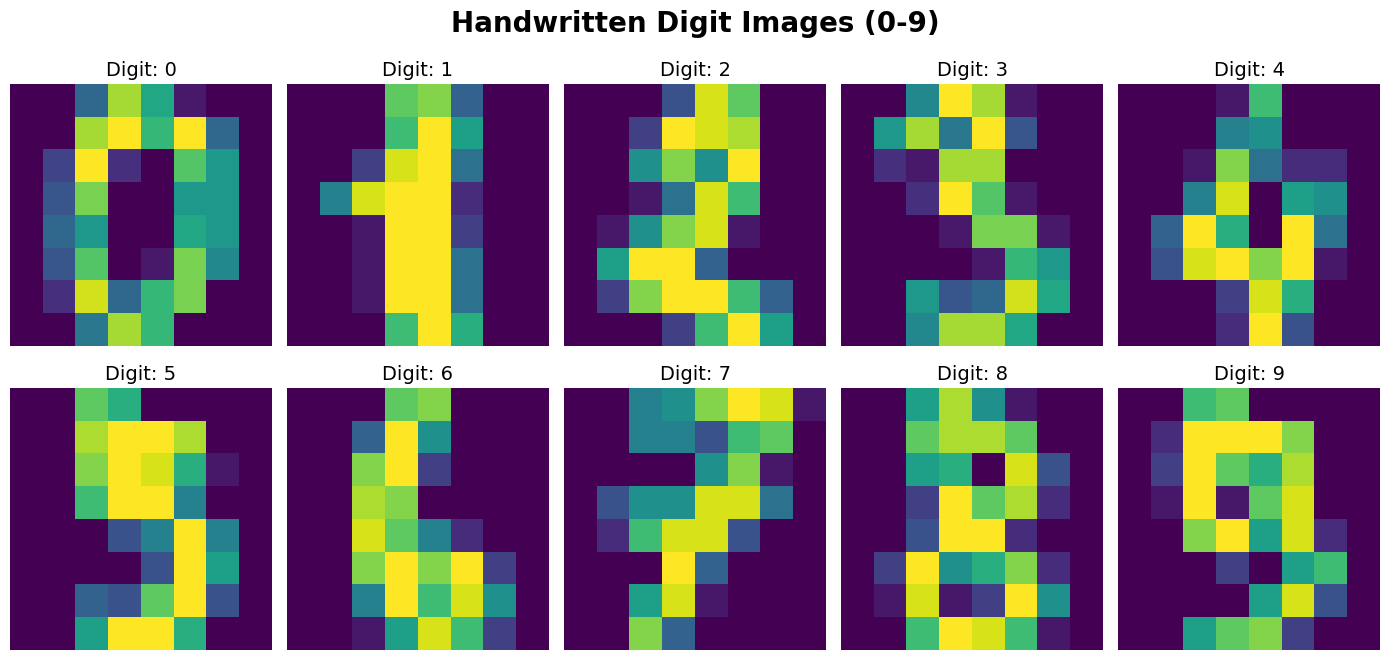

In [7]:
plt.figure(figsize=(14, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(digits.images[i], cmap='viridis')

    plt.title(f"Digit: {digits.target[i]}", fontsize=14)
    plt.axis('off')

plt.suptitle("Handwritten Digit Images (0-9)",
             fontsize=20, fontweight='bold')

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# Features (X) and Labels (y)
X = digits.data
y = digits.target

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

Training Data Shape: (1437, 64)
Testing Data Shape: (360, 64)
Training Labels Shape: (1437,)
Testing Labels Shape: (360,)


In [9]:
from sklearn.neighbors import KNeighborsClassifier

In [10]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=3)

# Train the model
knn.fit(X_train, y_train)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [11]:
# Predict test data
y_pred = knn.predict(X_test)

# Calculate accuracy
accuracy = knn.score(X_test, y_test)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.33333333333333 %


In [12]:
from sklearn.neighbors import KNeighborsClassifier

k_values = [1, 3, 5, 9]

results = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    accuracy = model.score(X_test, y_test)

    results.append(accuracy * 100)

    print(f"K = {k}, Accuracy = {accuracy * 100:.2f}%")

K = 1, Accuracy = 97.78%
K = 3, Accuracy = 98.33%
K = 5, Accuracy = 98.61%
K = 9, Accuracy = 98.06%


In [13]:
import pandas as pd

comparison = pd.DataFrame({
    'K Value': k_values,
    'Accuracy (%)': results
})

print(comparison)

   K Value  Accuracy (%)
0        1     97.777778
1        3     98.333333
2        5     98.611111
3        9     98.055556


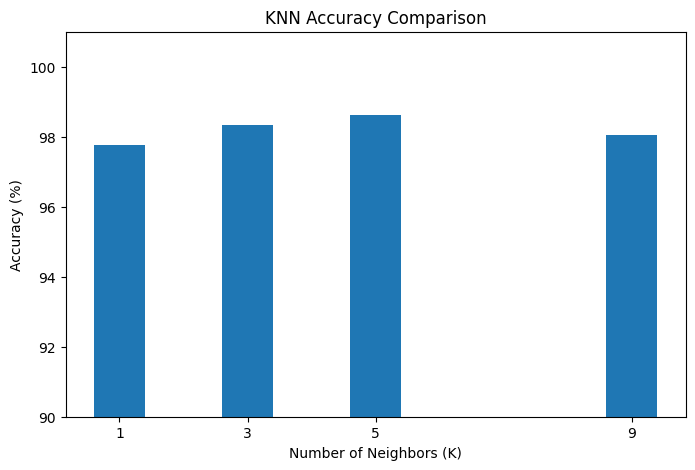

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(k_values, results)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy (%)")

plt.title("KNN Accuracy Comparison")

plt.xticks(k_values)
plt.ylim(90, 101)

plt.show()

In [15]:
# Create best KNN model
best_model = KNeighborsClassifier(n_neighbors=5)

# Train model
best_model.fit(X_train, y_train)

# Predict test images
y_pred = best_model.predict(X_test)

print("Best KNN Model Trained Successfully!")

Best KNN Model Trained Successfully!


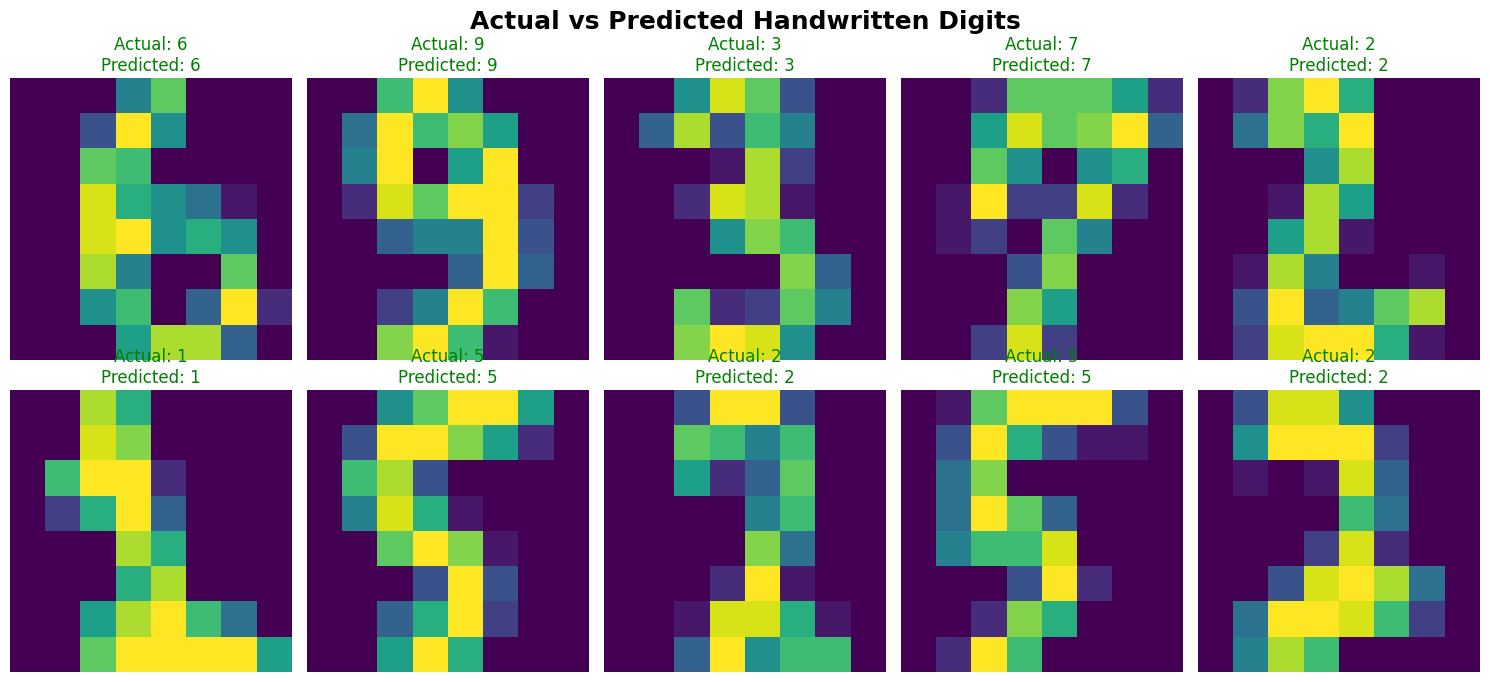

In [16]:
plt.figure(figsize=(15, 7))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    image = X_test[i].reshape(8, 8)

    plt.imshow(image, cmap='viridis')

    actual = y_test[i]
    predicted = y_pred[i]

    if actual == predicted:
        color = 'green'
    else:
        color = 'red'

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=12
    )

    plt.axis('off')

plt.suptitle(
    "Actual vs Predicted Handwritten Digits",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [17]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate final accuracy
final_accuracy = accuracy_score(y_test, y_pred)

print("Final Model Accuracy:", round(final_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Final Model Accuracy: 98.61 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      1.00      1.00        34
           4       0.98      1.00      0.99        46
           5       0.98      0.96      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.97      0.99        34
           8       1.00      1.00      1.00        30
           9       0.95      0.95      0.95        40

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



In [18]:
readme_content = """
# Handwritten Digit Classifier

## Project Overview
This project identifies handwritten digits (0-9)
using Machine Learning and the K-Nearest Neighbors
(KNN) algorithm.

## Dataset
- Dataset: Scikit-learn Digits Dataset
- Total Images: 1797
- Image Size: 8x8 pixels
- Classes: 0 to 9

## Technologies Used
- Python
- NumPy
- Matplotlib
- Pandas
- Scikit-learn
- Google Colab

## Machine Learning Algorithm
K-Nearest Neighbors (KNN)

## Train-Test Split
- Training Data: 80%
- Testing Data: 20%

## K Value Comparison

| K Value | Accuracy |
|---------|----------|
| 1 | 97.78% |
| 3 | 98.33% |
| 5 | 98.61% |
| 9 | 98.06% |

## Best Model
KNN with K = 5

## Final Accuracy
98.61%

## Conclusion
The model successfully classifies handwritten
digits with 98.61% test accuracy.
"""

readme_path = os.path.join(project_path, "README.md")

with open(readme_path, "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [19]:
from google.colab import files

files.download('/content/drive/MyDrive/SkillMe_Projects /Handwritten_Digit_Classifier.ipynb')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
files.download('/content/drive/MyDrive/SkillMe_Projects /README.md')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [22]:
# Define 4 Machine Learning Models

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True),
    "Random Forest": RandomForestClassifier(random_state=42)
}

print("4 Models Created Successfully!")

4 Models Created Successfully!


In [23]:
# Compare Models using 5-Fold Cross Validation

results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    results.append({
        "Model": name,
        "Accuracy": scores.mean() * 100
    })

    print(name)
    print("Cross Validation Accuracy:", scores.mean() * 100)
    print("--------------------------------")

results_df = pd.DataFrame(results)

print(results_df)

Logistic Regression
Cross Validation Accuracy: 95.33633372048004
--------------------------------
KNN
Cross Validation Accuracy: 98.32921989934185
--------------------------------
SVM
Cross Validation Accuracy: 98.60820751064654
--------------------------------
Random Forest
Cross Validation Accuracy: 97.35554587688733
--------------------------------
                 Model   Accuracy
0  Logistic Regression  95.336334
1                  KNN  98.329220
2                  SVM  98.608208
3        Random Forest  97.355546


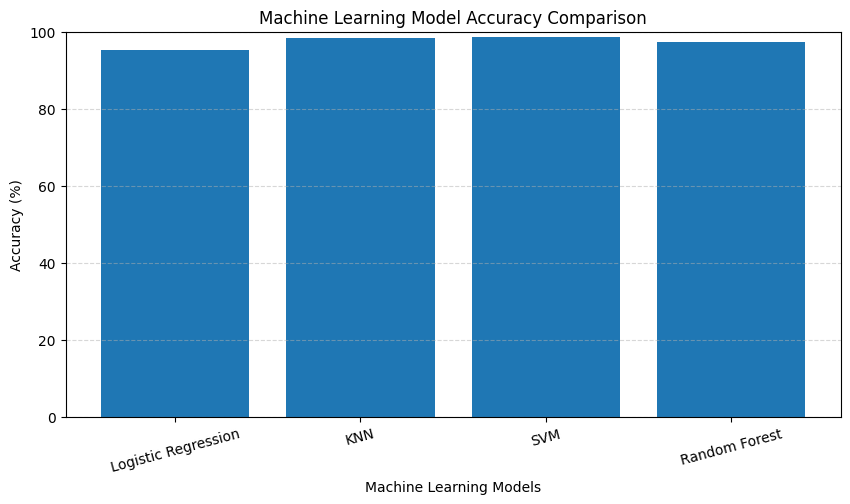

In [24]:
# Model Accuracy Comparison

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=15)
plt.ylim(0, 100)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create SVM Pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC())
])

# Train the model
svm_pipeline.fit(X_train, y_train)

# Make predictions
y_pred_scaled = svm_pipeline.predict(X_test)

# Calculate accuracy
scaled_accuracy = accuracy_score(y_test, y_pred_scaled)

print("Scaled SVM Accuracy:", scaled_accuracy * 100, "%")

Scaled SVM Accuracy: 98.05555555555556 %


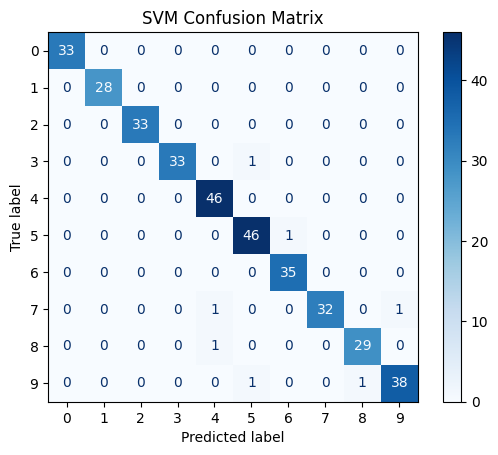

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Display Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    svm_pipeline,
    X_test,
    y_test,
    cmap='Blues',
    values_format='d'
)

plt.title("SVM Confusion Matrix")
plt.show()

Total Misclassified Images: 7


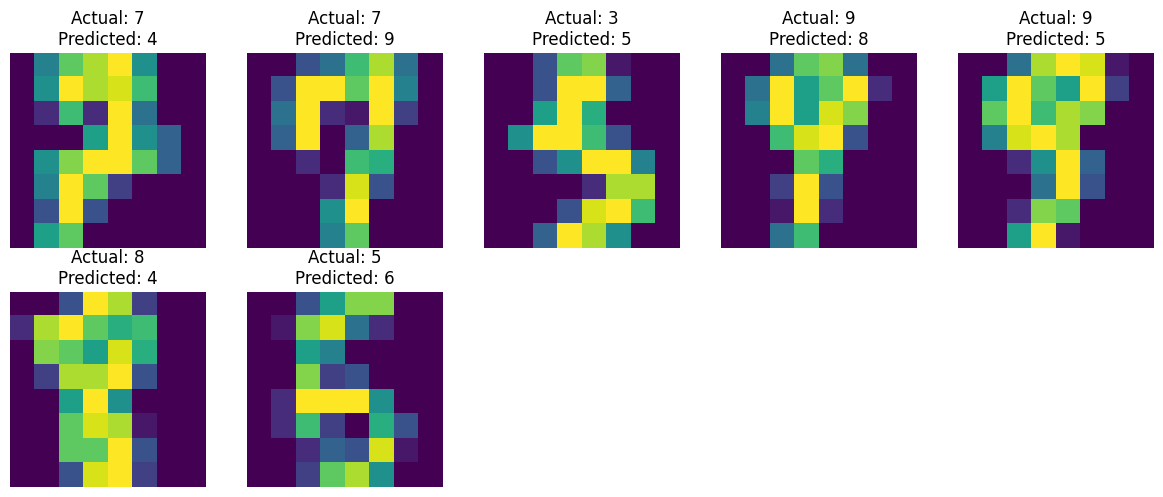

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# Find incorrect predictions
misclassified = np.where(y_pred_scaled != y_test)[0]

print("Total Misclassified Images:", len(misclassified))

# Display up to 10 incorrect images
plt.figure(figsize=(12, 5))

for i, index in enumerate(misclassified[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[index].reshape(8, 8), cmap='viridis')

    plt.title(
        f"Actual: {y_test.iloc[index] if hasattr(y_test, 'iloc') else y_test[index]}\n"
        f"Predicted: {y_pred_scaled[index]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [30]:
from sklearn.datasets import fetch_openml

# Load MNIST dataset
mnist = fetch_openml('mnist_784', version=1, as_frame=False)

# Separate images and labels
X_mnist = mnist.data
y_mnist = mnist.target.astype(int)

print("MNIST Dataset Shape:", X_mnist.shape)
print("MNIST Labels Shape:", y_mnist.shape)

MNIST Dataset Shape: (70000, 784)
MNIST Labels Shape: (70000,)


In [31]:
X_mnist = X_mnist / 255.0

print("Normalized Pixel Values:")
print("Minimum:", X_mnist.min())
print("Maximum:", X_mnist.max())

Normalized Pixel Values:
Minimum: 0.0
Maximum: 1.0


In [32]:
from sklearn.model_selection import train_test_split

X_subset, _, y_subset, _ = train_test_split(
    X_mnist,
    y_mnist,
    train_size=10000,
    random_state=42,
    stratify=y_mnist
)

# Split into training and testing data
X_mnist_train, X_mnist_test, y_mnist_train, y_mnist_test = train_test_split(
    X_subset,
    y_subset,
    test_size=0.2,
    random_state=42,
    stratify=y_subset
)

print("Training Data:", X_mnist_train.shape)
print("Testing Data:", X_mnist_test.shape)

Training Data: (8000, 784)
Testing Data: (2000, 784)


In [33]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create SVM model
mnist_model = SVC(kernel='rbf')

# Train model
mnist_model.fit(X_mnist_train, y_mnist_train)

# Make predictions
mnist_predictions = mnist_model.predict(X_mnist_test)

# Calculate accuracy
mnist_accuracy = accuracy_score(
    y_mnist_test,
    mnist_predictions
)

print("MNIST Test Accuracy:", mnist_accuracy * 100, "%")

MNIST Test Accuracy: 95.7 %


In [34]:
import joblib
import os

# Save model in Google Drive
save_path = "/content/drive/MyDrive/SkillMe_Projects /digit_model.joblib"

joblib.dump(mnist_model, save_path)

print("Model saved successfully!")
print("File location:", save_path)

Model saved successfully!
File location: /content/drive/MyDrive/SkillMe_Projects /digit_model.joblib


In [35]:
import joblib

# Load saved model
loaded_model = joblib.load(save_path)

# Make predictions
predictions = loaded_model.predict(X_mnist_test[:5])

print("Predictions:", predictions)
print("Actual Labels:", y_mnist_test[:5])

Predictions: [8 2 1 2 9]
Actual Labels: [8 2 1 2 9]


In [38]:
from google.colab import files

files.download('/content/drive/MyDrive/SkillMe_Projects /digit_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>